## Imports
### (pandas, numpy, sci-kit learn...)

In [ ]:
import numpy as np
import pandas as pd # pandas (ej: lector de .csv)
import matplotlib.pyplot as plt #grafico
import seaborn as sns #grafico
from sklearn.ensemble import RandomForestClassifier  #nuestro modelo
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split #herramienta de splitting
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report #metricas

### Carga de datos, exploracion, limpieza, segregación.

In [2]:
dataraw = pd.read_csv('/home/psy/estudios/facultad/2do cuatrimestre 1er año/clase_compartida/equipos.csv')

In [3]:
dataraw.shape

(24, 5)

In [4]:
dataraw.isnull().sum()

horas_uso           0
temperatura         0
vibracion           0
antiguedad_anios    0
falla               0
dtype: int64

In [5]:
dataraw.head()

,horas_uso,temperatura,vibracion,antiguedad_anios,falla
0,2.1,54.6,1.4,1.6,no
1,5.4,69.9,6.0,0.7,si
2,6.3,47.1,3.0,3.9,si
3,1.3,83.3,4.3,8.9,si
4,2.3,87.5,0.8,6.2,no


In [6]:
X = dataraw.drop(['falla'], axis=1)
y = dataraw['falla']

In [7]:
X.head(2)

,horas_uso,temperatura,vibracion,antiguedad_anios
0,2.1,54.6,1.4,1.6
1,5.4,69.9,6.0,0.7


## Bootstrapping : ¿Que es, y por que sirve para la varianza?

![Alt text](https://miro.medium.com/v2/1*cmA1PPO4Us6_okb5UMhb0Q.jpeg)

#### muestreo de filas

![Alt text](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcTM2ilt5F2opndq3KlbfKdWbS8Ha_tDXrkbQZLRknOZw4fWzVNVG8VmSbOO&s=10)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.80, random_state=42)

In [9]:
Random_Forest_C = RandomForestClassifier(n_estimators=300, criterion="gini", max_features=2, max_depth=12, n_jobs=1, random_state=42,verbose=1)

Random_Forest_C.fit(X_train, y_train)

y_pred_rf = Random_Forest_C.predict(X_test)

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.1s


[Parallel(n_jobs=1)]: Done 199 tasks      | elapsed:    0.3s
[Parallel(n_jobs=1)]: Done 300 out of 300 | elapsed:    0.4s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 199 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 300 out of 300 | elapsed:    0.0s finished


![](zona_diffuse.png)

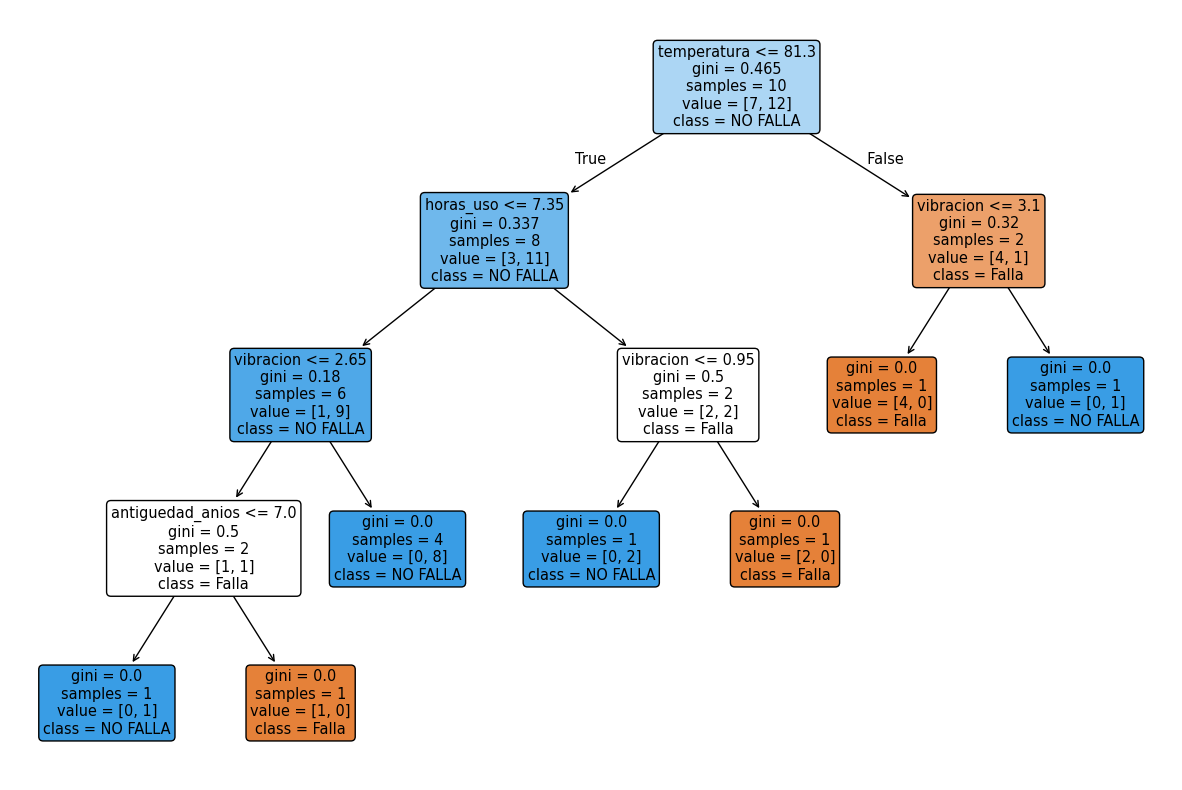

In [10]:
from sklearn.tree import plot_tree
plt.figure(figsize=(15, 10))
plot_tree(Random_Forest_C.estimators_[0], 
          feature_names=list(X_train.columns),  
          class_names=["Falla","NO FALLA"], 
          filled=True, 
          rounded=True,
          max_depth=5,
          )
plt.show()

![Alt text](https://media.geeksforgeeks.org/wp-content/uploads/20260306111717662229/random_forest_algorithm.webp)

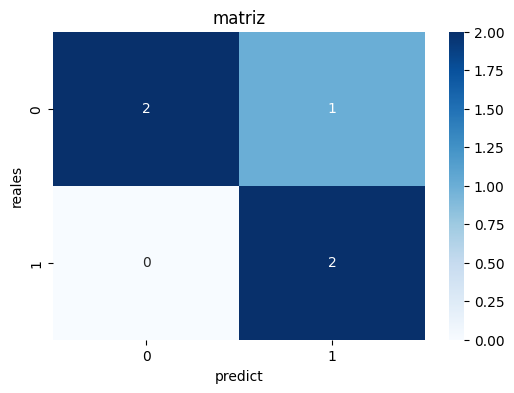

              precision    recall  f1-score   support

          no       1.00      0.67      0.80         3
          si       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5



In [11]:
cm=confusion_matrix(y_test,y_pred_rf)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt='g',cmap='Blues')
plt.title('matriz')
plt.xlabel('predict')
plt.ylabel('reales')
plt.show()


print(classification_report(y_test,y_pred_rf))

In [ ]:
# recall 67% - 33%

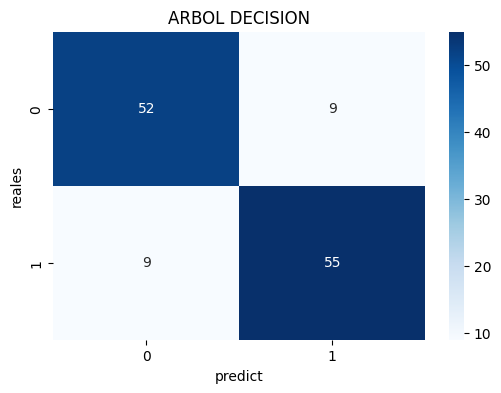

              precision    recall  f1-score   support

           0       0.85      0.85      0.85        61
           1       0.86      0.86      0.86        64

    accuracy                           0.86       125
   macro avg       0.86      0.86      0.86       125
weighted avg       0.86      0.86      0.86       125



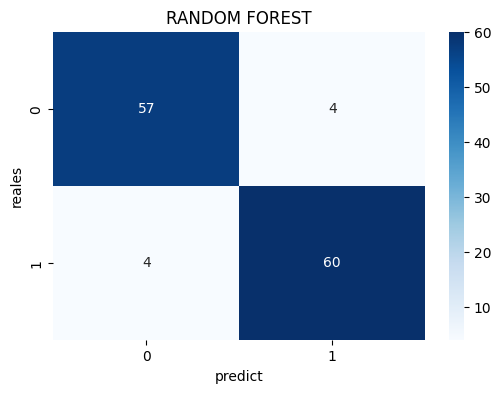

              precision    recall  f1-score   support

           0       0.93      0.93      0.93        61
           1       0.94      0.94      0.94        64

    accuracy                           0.94       125
   macro avg       0.94      0.94      0.94       125
weighted avg       0.94      0.94      0.94       125



In [12]:
#COMPARACION ENTRE MODELOS CON DATASETS GRANDES 100% SINTETICOS:

from sklearn.datasets import make_classification

X_big, y_big = make_classification(
    n_samples=500, n_features=4,
    n_informative=3, n_redundant=0,
    random_state=42
)

#375 datos entrenamiento ; 125 datos de testeo/prueba
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_big, y_big, train_size=0.75, random_state=42, stratify=y_big)

#MAXDEPTH iguales para ambos modelos
arbol  = DecisionTreeClassifier(max_depth=12, random_state=42).fit(Xb_train, yb_train)
bosque = RandomForestClassifier(n_estimators=300, max_features=2, max_depth=12, random_state=42).fit(Xb_train, yb_train)

arbol_pr = arbol.predict(Xb_test)
bosque_pr = bosque.predict(Xb_test)

# sns arbol decision
cm=confusion_matrix(yb_test, arbol_pr)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt='g',cmap='Blues')
plt.title('ARBOL DECISION')
plt.xlabel('predict')
plt.ylabel('reales')
plt.show()

print(classification_report(yb_test, arbol_pr))

# sns random forest
cm=confusion_matrix(yb_test, bosque_pr)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt='g',cmap='Blues')
plt.title('RANDOM FOREST')
plt.xlabel('predict')
plt.ylabel('reales')
plt.show()


print(classification_report(yb_test, bosque_pr))